# Customer Churn Prediction & Analysis

## 1. Business Understanding

### Business Problem

Customer churn is a major challenge for subscription-based businesses because losing existing customers can negatively affect revenue and customer lifetime value.

The objective of this project is to identify customers who are at higher risk of churn, understand the factors associated with customer attrition, and translate the findings into actionable customer retention strategies.

### Project Objectives

- Understand the characteristics of the customer base
- Identify factors associated with customer churn
- Explore customer segments with higher churn risk
- Develop and compare machine learning classification models
- Optimize the classification threshold based on the business objective
- Interpret model results
- Translate analytical findings into actionable business recommendations

### Business Questions

1. Which customer segments have the highest churn rates?
2. Which customer characteristics are associated with churn?
3. How accurately can we identify customers at high risk of churn?
4. Which machine learning model performs best for this problem?
5. How can churn predictions support customer retention strategies?


## 2. Data Understanding

The dataset contains customer-level information including demographic characteristics, service subscriptions, contract details, payment methods, tenure, monthly charges, total charges, and churn status.

The target variable is `Churn`, which indicates whether a customer has left the company.

In [467]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, mannwhitneyu
from sklearn.metrics import roc_curve
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

from xgboost import XGBClassifier


### Load Dataset

In [468]:
df = pd.read_csv("../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv")

## 2. Data Quality Assessment

Before performing exploratory analysis, the dataset is inspected for its structure, data types, missing values, duplicates, and potential data quality issues.

In [469]:
print(f"Dataset contains {df.shape[0]:,} rows and {df.shape[1]} columns.")

Dataset contains 7,043 rows and 21 columns.


In [470]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [471]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


### Missing Values

In [472]:
df.isnull().sum().sort_values(ascending=False)

customerID          0
DeviceProtection    0
TotalCharges        0
MonthlyCharges      0
PaymentMethod       0
PaperlessBilling    0
Contract            0
StreamingMovies     0
StreamingTV         0
TechSupport         0
OnlineBackup        0
gender              0
OnlineSecurity      0
InternetService     0
MultipleLines       0
PhoneService        0
tenure              0
Dependents          0
Partner             0
SeniorCitizen       0
Churn               0
dtype: int64

### Duplicate Records

In [473]:
df.duplicated().sum()

0

### Data Type Validation

`TotalCharges` should be a numeric variable because it represents the total amount charged to a customer. Its data type will therefore be investigated before preprocessing.


In [474]:
df.dtypes

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

In [475]:
df["TotalCharges"].value_counts(dropna=False).head(10)

TotalCharges
         11
20.2     11
19.75     9
20.05     8
19.9      8
19.65     8
45.3      7
19.55     7
20.15     6
20.25     6
Name: count, dtype: int64

### Investigating Blank `TotalCharges` Values

The `TotalCharges` column contains blank string values. Before deciding how to handle them, we investigate whether these records share any common characteristics.

In [476]:
blank_total_charges = df[df["TotalCharges"].str.strip() == ""]

blank_total_charges[["tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,,No
753,0,20.25,,No
936,0,80.85,,No
1082,0,25.75,,No
1340,0,56.05,,No
3331,0,19.85,,No
3826,0,25.35,,No
4380,0,20.00,,No
5218,0,19.70,,No
6670,0,73.35,,No


In [477]:
blank_total_charges["tenure"].value_counts()

tenure
0    11
Name: count, dtype: int64

### Findings from `TotalCharges` Investigation

The `TotalCharges` column contains 11 blank string values.

All 11 records have a tenure of 0 months, indicating that these customers are newly acquired and have not accumulated total charges yet. Their `Churn` status is also `No`.

Because these records represent valid customers rather than invalid observations, the blank `TotalCharges` values will be treated as zero during preprocessing.

## 3. Data Cleaning

### Convert `TotalCharges` to Numeric

In [478]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

In [479]:
df["TotalCharges"].isna().sum()

11

In [480]:
df.loc[df["TotalCharges"].isna(), "TotalCharges"] = 0

In [481]:
df["TotalCharges"].isna().sum()

0

In [482]:
df["TotalCharges"].dtype

dtype('float64')

## 4. Exploratory Data Analysis

### 4.1 Target Variable Distribution

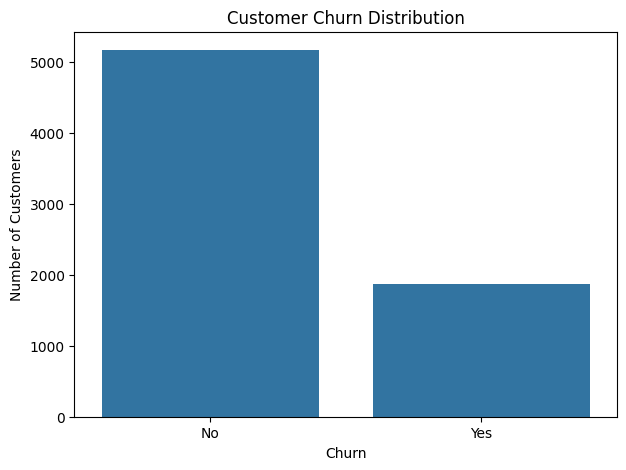

In [483]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

### Finding

The dataset contains more customers who did not churn than customers who churned, indicating an imbalance in the target variable.

### Business Implication

Because churn represents the minority class, accuracy alone may not be sufficient to evaluate model performance. Precision, recall, F1-score, and ROC-AUC will also be considered during model evaluation.

### 4.2 Churn Rate by Contract Type

Contract type is an important customer characteristic because it reflects the level of customer commitment. Churn rates are compared across contract types to identify segments with higher customer attrition.

In [484]:
contract_churn = (
    df.groupby("Contract")["Churn"]
      .apply(lambda x: (x == "Yes").mean() * 100)
      .sort_values(ascending=False)
)

contract_churn

Contract
Month-to-month    42.709677
One year          11.269518
Two year           2.831858
Name: Churn, dtype: float64

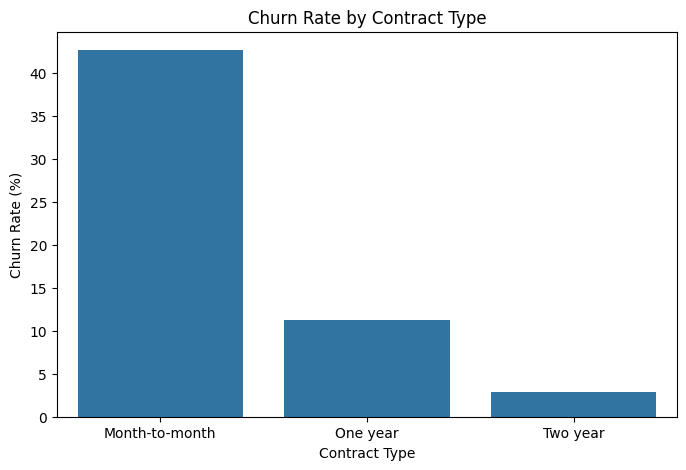

In [485]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=contract_churn.index,
    y=contract_churn.values
)

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")

plt.show()

In [486]:
contract_churn

Contract
Month-to-month    42.709677
One year          11.269518
Two year           2.831858
Name: Churn, dtype: float64

### Finding

Contract type is strongly associated with customer churn.

Customers on month-to-month contracts have the highest churn rate at 42.71%, compared with 11.27% for one-year contracts and only 2.83% for two-year contracts.

### Business Implication

Month-to-month customers represent a high-priority segment for churn prevention. The business could consider targeted retention strategies for these customers, such as personalized offers, contract incentives, or proactive engagement before renewal decisions.

### 4.3 Churn Rate by Tenure

In [487]:
tenure_bins = [0, 12, 24, 48, 72]
tenure_labels = ["0-12 months", "13-24 months", "25-48 months", "49-72 months"]

df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=tenure_bins,
    labels=tenure_labels,
    include_lowest=True
)

In [488]:
tenure_churn = (
    df.groupby("TenureGroup", observed=False)["Churn"]
      .apply(lambda x: (x == "Yes").mean() * 100)
)

tenure_churn.round(2).to_frame("Churn Rate (%)")

,Churn Rate (%)
TenureGroup,
0-12 months,47.44
13-24 months,28.71
25-48 months,20.39
49-72 months,9.51


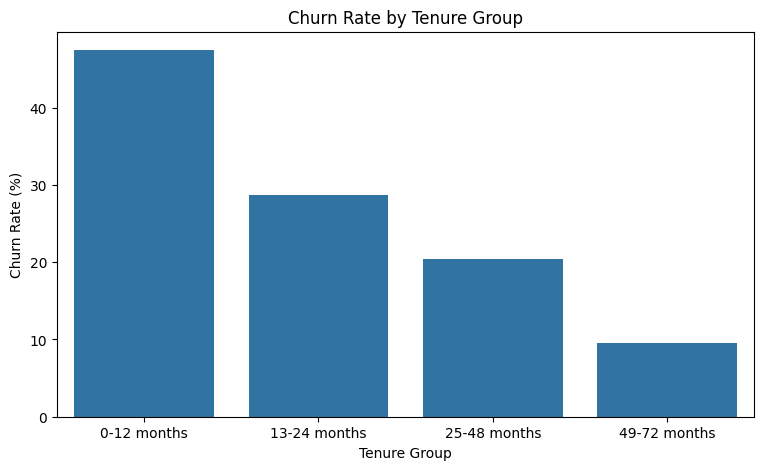

In [489]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=tenure_churn.index,
    y=tenure_churn.values
)

plt.title("Churn Rate by Tenure Group")
plt.xlabel("Tenure Group")
plt.ylabel("Churn Rate (%)")

plt.show()

### 4.4 Churn Rate by Monthly Charges

Monthly charges are grouped into customer segments to examine whether churn rates differ across pricing levels.

In [490]:
charge_bins = [0, 30, 60, 90, 120]
charge_labels = ["$0-30", "$31-60", "$61-90", "$91-120"]

df["MonthlyChargesGroup"] = pd.cut(
    df["MonthlyCharges"],
    bins=charge_bins,
    labels=charge_labels,
    include_lowest=True
)

In [491]:
charge_churn = (
    df.groupby("MonthlyChargesGroup", observed=False)["Churn"]
      .apply(lambda x: (x == "Yes").mean() * 100)
)

charge_churn.round(2).to_frame("Churn Rate (%)")

,Churn Rate (%)
MonthlyChargesGroup,
$0-30,9.80
$31-60,25.93
$61-90,33.91
$91-120,32.78


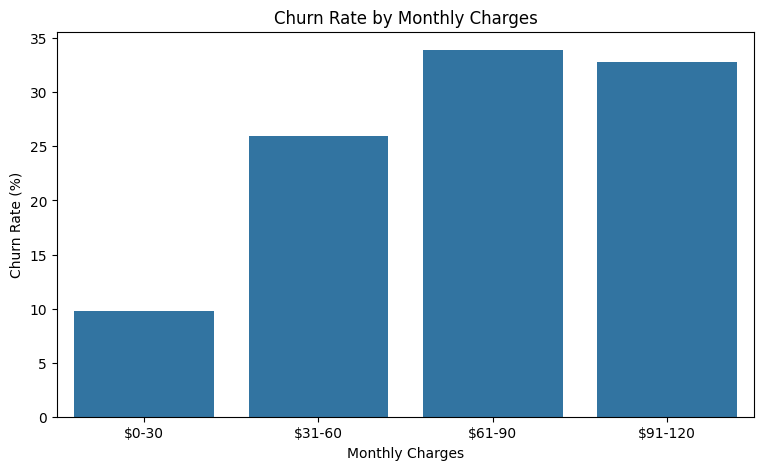

In [492]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=charge_churn.index,
    y=charge_churn.values
)

plt.title("Churn Rate by Monthly Charges")
plt.xlabel("Monthly Charges")
plt.ylabel("Churn Rate (%)")

plt.show()

### Finding

Churn rates increase substantially as monthly charges rise.

Customers paying $0-30 per month have the lowest churn rate at 9.80%. Churn increases to 25.93% for customers paying $31-60 and reaches 33.91% among customers paying $61-90. Customers paying $91-120 have a similarly high churn rate of 32.78%.

### Business Implication

Higher-charge customer segments represent an important group for churn prevention. However, monthly charges may also reflect differences in services, contracts, or customer segments. Therefore, monthly charges should be considered together with other customer characteristics rather than treated as an isolated driver of churn.

### 4.5 Churn Rate by Internet Service

Internet service type is analyzed to identify whether churn rates differ across customer service categories.

In [493]:
internet_churn = (
    df.groupby("InternetService")["Churn"]
      .apply(lambda x: (x == "Yes").mean() * 100)
)

internet_churn.round(2).to_frame("Churn Rate (%)")

,Churn Rate (%)
InternetService,
DSL,18.96
Fiber optic,41.89
No,7.40


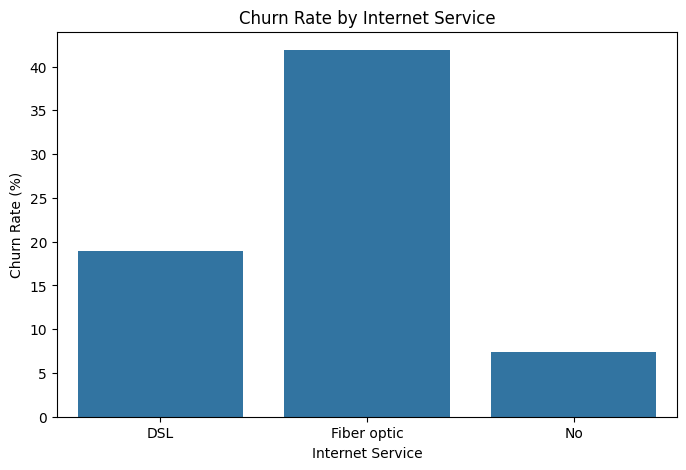

In [494]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=internet_churn.index,
    y=internet_churn.values
)

plt.title("Churn Rate by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Churn Rate (%)")

plt.show()

### Finding

Churn rates differ substantially across internet service types.

Fiber optic customers have the highest churn rate at 41.89%, compared with 18.96% for DSL customers. Customers without internet service have the lowest churn rate at 7.40%.

### Business Implication

Fiber optic customers represent a high-priority segment for churn prevention. The business should investigate whether pricing, service quality, support experience, or other customer characteristics may be associated with the higher churn observed in this segment.

These results indicate an association rather than causation and should be evaluated alongside other customer characteristics.

### 4.6 Churn Rate by Payment Method

In [495]:
payment_churn = (
    df.groupby("PaymentMethod")["Churn"]
      .apply(lambda x: (x == "Yes").mean() * 100)
)

payment_churn.round(2).to_frame("Churn Rate (%)")

,Churn Rate (%)
PaymentMethod,
Bank transfer (automatic),16.71
Credit card (automatic),15.24
Electronic check,45.29
Mailed check,19.11


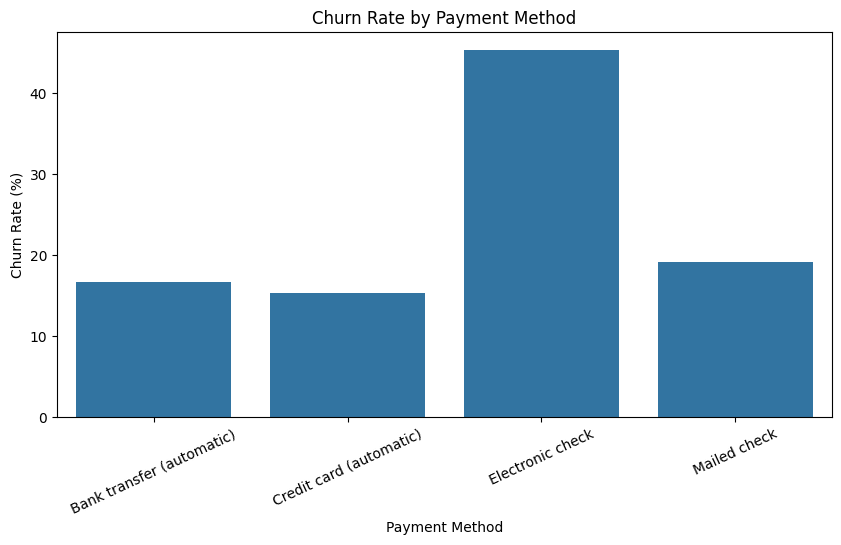

In [496]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=payment_churn.index,
    y=payment_churn.values
)

plt.title("Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=25)

plt.show()

### Finding

Churn rates vary substantially across payment methods.

Customers using electronic check have the highest churn rate at 45.29%, while customers using automatic bank transfer and automatic credit card payments have considerably lower churn rates of 16.71% and 15.24%, respectively.

### Business Implication

Customers using electronic check represent a high-priority segment for churn prevention. The business could investigate whether payment convenience, billing experience, or customer characteristics associated with this payment method contribute to the higher churn rate.

The observed relationship represents an association and does not by itself establish causation.

### 4.7 Churn Rate by Number of Additional Services

In [497]:
service_cols = [
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies"
]

df["AdditionalServicesCount"] = (
    df[service_cols]
    .apply(lambda row: (row == "Yes").sum(), axis=1)
)

In [498]:
services_churn = (
    df.groupby("AdditionalServicesCount")["Churn"]
      .apply(lambda x: (x == "Yes").mean() * 100)
)

services_churn.round(2).to_frame("Churn Rate (%)")

,Churn Rate (%)
AdditionalServicesCount,
0,21.41
1,45.76
2,35.82
3,27.37
4,22.30
5,12.43
6,5.28


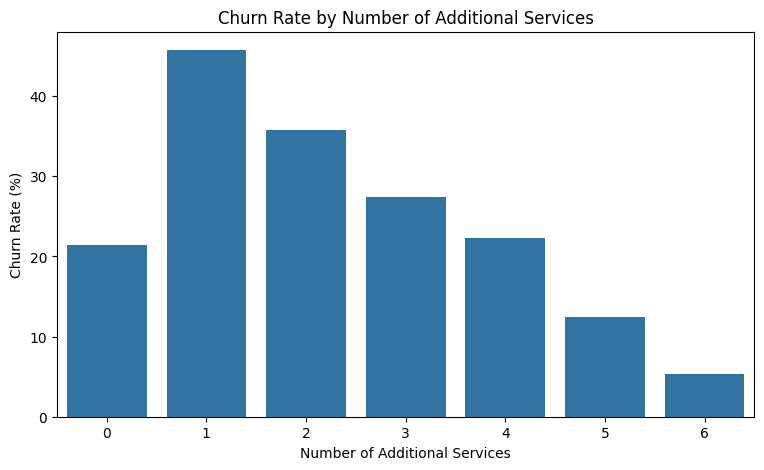

In [499]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=services_churn.index,
    y=services_churn.values
)

plt.title("Churn Rate by Number of Additional Services")
plt.xlabel("Number of Additional Services")
plt.ylabel("Churn Rate (%)")

plt.show()

### Finding

Churn rates vary considerably based on the number of additional services used by customers.

Customers with one additional service have the highest observed churn rate at 45.76%. In contrast, churn decreases substantially among customers with a higher number of additional services, reaching 5.28% for customers using all six additional services.

Overall, customers with more additional services tend to show lower churn rates, although the relationship is not strictly linear.

### Business Implication

Customers with limited service adoption may represent an opportunity for targeted engagement and retention strategies. Encouraging relevant service adoption could potentially increase customer engagement and strengthen the overall customer relationship.

However, the observed relationship is associative rather than causal. Additional analysis is required before treating service adoption as a direct churn-reduction strategy.

### 4.8 Monthly Charges Distribution by Churn

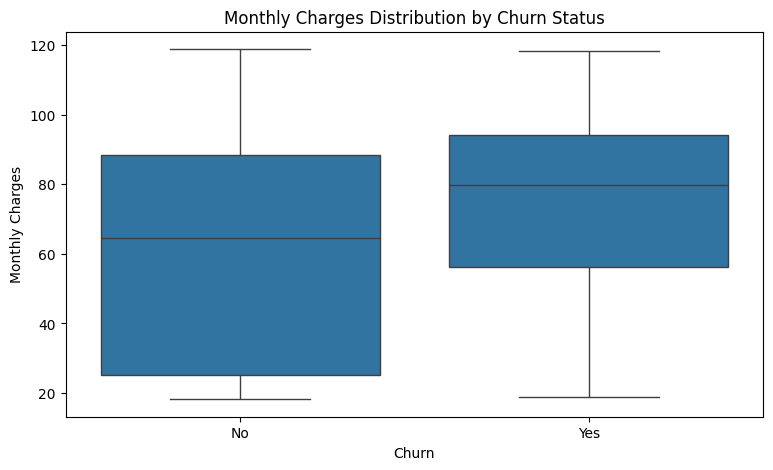

In [500]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges Distribution by Churn Status")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")

plt.show()

In [501]:
df.groupby("Churn")["MonthlyCharges"].agg(["median", "mean"]).round(2)

,median,mean
Churn,,
No,64.43,61.27
Yes,79.65,74.44


### Finding

Customers who churned tend to have higher monthly charges than customers who remained with the company.

The median monthly charge is $79.65 for churned customers compared with $64.43 for non-churned customers. The mean monthly charge shows a similar pattern, at $74.44 for churned customers versus $61.27 for non-churned customers.

### Business Implication

Higher monthly charges are associated with higher churn risk in this dataset. Higher-paying customers may therefore warrant additional attention in retention strategies.

However, monthly charges may be related to other factors such as contract type, internet service, and service adoption. Therefore, this relationship should not be interpreted as evidence that higher prices directly cause churn.

## 5. Statistical Analysis

Exploratory analysis identified several customer characteristics associated with churn. Statistical testing is used to determine whether selected categorical variables show a statistically significant association with the target variable.

### 5.1 Chi-Square Test: Contract Type and Churn

A chi-square test of independence is used to evaluate whether customer contract type is statistically associated with churn.

- **Null hypothesis (H₀):** Contract type and churn are independent.
- **Alternative hypothesis (H₁):** Contract type and churn are associated.

In [502]:
contract_table = pd.crosstab(df["Contract"], df["Churn"])

chi2, p_value, dof, expected = chi2_contingency(contract_table)

print(f"Chi-square statistic: {chi2:.2f}")
print(f"p-value: {p_value:.4f}")
print(f"Degrees of freedom: {dof}")

Chi-square statistic: 1184.60
p-value: 0.0000
Degrees of freedom: 2


In [503]:
contract_table

Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1307,166
Two year,1647,48


### Interpretation

The chi-square test indicates a statistically significant association between contract type and churn (χ² = 1184.60, df = 2, p < 0.001).

Therefore, the null hypothesis of independence is rejected.

This result supports the exploratory finding that churn rates differ substantially across contract types.

However, statistical association does not imply that contract type directly causes churn.

### 5.2 Chi-Square Test: Internet Service and Churn

A chi-square test of independence is used to evaluate whether internet service type is statistically associated with churn.

- **Null hypothesis (H₀):** Internet service type and churn are independent.
- **Alternative hypothesis (H₁):** Internet service type and churn are associated.

In [504]:
internet_table = pd.crosstab(df["InternetService"], df["Churn"])

chi2, p_value, dof, expected = chi2_contingency(internet_table)

print(f"Chi-square statistic: {chi2:.2f}")
print(f"p-value: {p_value:.4f}")
print(f"Degrees of freedom: {dof}")

Chi-square statistic: 732.31
p-value: 0.0000
Degrees of freedom: 2


In [505]:
internet_table

Churn,No,Yes
InternetService,,
DSL,1962,459
Fiber optic,1799,1297
No,1413,113


### Interpretation

The chi-square test indicates a statistically significant association between internet service type and churn (χ² = 732.31, df = 2, p < 0.001).

Therefore, the null hypothesis of independence is rejected.

This result supports the exploratory finding that churn rates differ substantially across internet service types, with fiber optic customers showing a notably higher churn rate than DSL and customers without internet service.


### 5.3 Chi-Square Test: Payment Method and Churn

A chi-square test of independence is used to evaluate whether payment method is statistically associated with churn.

- **Null hypothesis (H₀):** Payment method and churn are independent.
- **Alternative hypothesis (H₁):** Payment method and churn are associated.

In [506]:
payment_table = pd.crosstab(df["PaymentMethod"], df["Churn"])

chi2, p_value, dof, expected = chi2_contingency(payment_table)

print(f"Chi-square statistic: {chi2:.2f}")
print(f"p-value: {p_value:.4f}")
print(f"Degrees of freedom: {dof}")

Chi-square statistic: 648.14
p-value: 0.0000
Degrees of freedom: 3


In [507]:
payment_table

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),1286,258
Credit card (automatic),1290,232
Electronic check,1294,1071
Mailed check,1304,308


### Interpretation

The chi-square test indicates a statistically significant association between payment method and churn (χ² = 648.14, df = 3, p < 0.001).

Therefore, the null hypothesis of independence is rejected.

This result supports the exploratory finding that churn rates differ substantially across payment methods, with electronic check customers showing a notably higher churn rate than customers using other payment methods.

However, statistical association does not imply that payment method directly causes churn.


## 6. Feature Engineering

Additional features are created to improve the representation of customer behavior and make the dataset suitable for machine learning.

### 6.1 Target Variable Encoding

In [508]:
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})

In [509]:
df["Churn"].value_counts()

Churn
0    5174
1    1869
Name: count, dtype: int64

### 6.2 Remove Unnecessary Identifier

The `customerID` column is a unique customer identifier and does not provide meaningful predictive information for churn modeling. It is therefore removed before model training.

In [510]:
"customerID" in df.columns

True

In [511]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn',
       'TenureGroup', 'MonthlyChargesGroup', 'AdditionalServicesCount'],
      dtype='object')

### 6.3 Categorical Variable Encoding

Categorical variables are converted into numerical representations using one-hot encoding so they can be used by machine learning algorithms.

In [512]:
categorical_cols = df.select_dtypes(include="object").columns.tolist()

categorical_cols

['customerID',
 'gender',
 'Partner',
 'Dependents',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod']

In [513]:
df.shape

(7043, 24)

In [514]:
df.dtypes

customerID                   object
gender                       object
SeniorCitizen                 int64
Partner                      object
Dependents                   object
tenure                        int64
PhoneService                 object
MultipleLines                object
InternetService              object
OnlineSecurity               object
OnlineBackup                 object
DeviceProtection             object
TechSupport                  object
StreamingTV                  object
StreamingMovies              object
Contract                     object
PaperlessBilling             object
PaymentMethod                object
MonthlyCharges              float64
TotalCharges                float64
Churn                         int64
TenureGroup                category
MonthlyChargesGroup        category
AdditionalServicesCount       int64
dtype: object

### 6.4 Handling EDA-Derived Variables

`TenureGroup` and `MonthlyChargesGroup` were created during exploratory analysis to investigate churn patterns. Since the original numerical variables `tenure` and `MonthlyCharges` are already available, these derived categorical variables are not retained for model training.

In [515]:
df = df.drop(columns=[
    "TenureGroup",
    "MonthlyChargesGroup"
])

In [516]:
df.shape

(7043, 22)

### 6.5 Define Features and Target

The target variable is separated from the predictor variables before model training.

`Churn` is used as the target variable, while all remaining variables are used as predictors.

In [517]:
X = df.drop(columns=["Churn", "customerID"])
y = df["Churn"]

In [518]:
print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

Feature matrix shape: (7043, 20)
Target shape: (7043,)


### 6.6 Train-Test Split

The dataset is divided into training and testing sets to evaluate model performance on unseen data.

The data is split into 80% training data and 20% testing data. Stratification is used to preserve the proportion of churned and non-churned customers in both sets.

In [519]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [520]:
print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (5634, 20)
Testing set: (1409, 20)


### 6.7 Preprocessing Pipeline

Preprocessing is performed within a pipeline to ensure that transformations are learned only from the training data and consistently applied to unseen data.

Numerical variables will be standardized, while categorical variables will be one-hot encoded.

In [521]:
numeric_features = [
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

categorical_features = [
    col for col in X_train.columns
    if col not in numeric_features
]

print("Numerical features:", numeric_features)
print("Number of categorical features:", len(categorical_features))

Numerical features: ['tenure', 'MonthlyCharges', 'TotalCharges']
Number of categorical features: 17


In [522]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numeric_features
        ),
        (
            "cat",
            OneHotEncoder(
                drop="first",
                handle_unknown="ignore"
            ),
            categorical_features
        )
    ]
)

## 7. Model Development

### 7.1 Logistic Regression

Logistic Regression is used as the baseline classification model for predicting customer churn.

In [523]:
logistic_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            LogisticRegression(
                max_iter=1000,
                random_state=42
            )
        )
    ]
)

In [524]:
logistic_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['tenure', 'MonthlyCharges',
                                                   'TotalCharges']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  ['gender', 'SeniorCitizen',
                                                   'Partner', 'Dependents',
                                                   'PhoneService',
                                                   'MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
                                                   'OnlineBackup',
                                                   'DeviceProtection',
                                                   'TechSupport', 'StreamingTV',
                                                   'StreamingMovies',
                                                   'Contract',
                                                   'PaperlessBilling',
                                                   'PaymentMethod',
                                                   'AdditionalServicesCount'])])),
                ('model', LogisticRegression(max_iter=1000, random_state=42))])

In [525]:
y_pred = logistic_pipeline.predict(X_test)
y_pred_proba = logistic_pipeline.predict_proba(X_test)[:, 1]

### 7.2 Model Evaluation

The baseline Logistic Regression model is evaluated using accuracy, precision, recall, F1-score, and ROC-AUC.

Because churn prediction is a business problem where identifying customers at risk of leaving is important, recall and ROC-AUC are considered alongside accuracy.

In [526]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_pred_proba)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")

Accuracy:  0.8027
Precision: 0.6481
Recall:    0.5615
F1-Score:  0.6017
ROC-AUC:   0.8424


### 7.3 Confusion Matrix

The confusion matrix provides a detailed view of the model's classification performance by showing correct and incorrect predictions for both churned and non-churned customers.

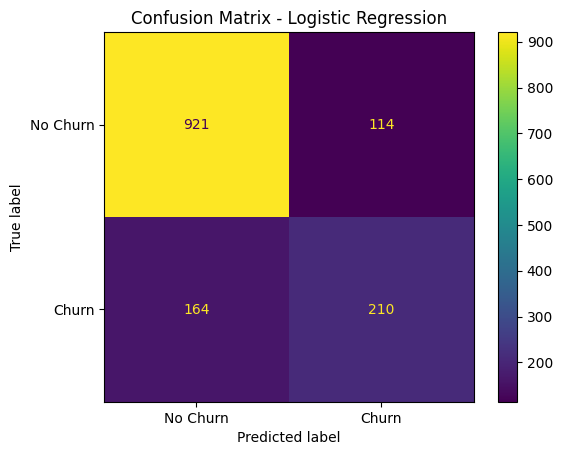

In [527]:
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
)

disp.plot()

plt.title("Confusion Matrix - Logistic Regression")
plt.show()

In [528]:
cm

array([[921, 114],
       [164, 210]], dtype=int64)

### Interpretation

The confusion matrix shows that the Logistic Regression model correctly identifies 921 non-churned customers and 210 churned customers.

However, the model incorrectly classifies 164 churned customers as non-churned. These false negatives represent customers who are actually at risk of leaving but are not identified by the model.

The model also incorrectly predicts churn for 114 customers who ultimately do not churn, resulting in false positive predictions.

Overall, the confusion matrix highlights the trade-off between identifying churned customers and avoiding false churn predictions. The number of false negatives also indicates that there may be an opportunity to improve churn detection through threshold optimization.

### 7.4 ROC Curve

The ROC curve illustrates the ability of the Logistic Regression model to distinguish between churned and non-churned customers across different classification thresholds.

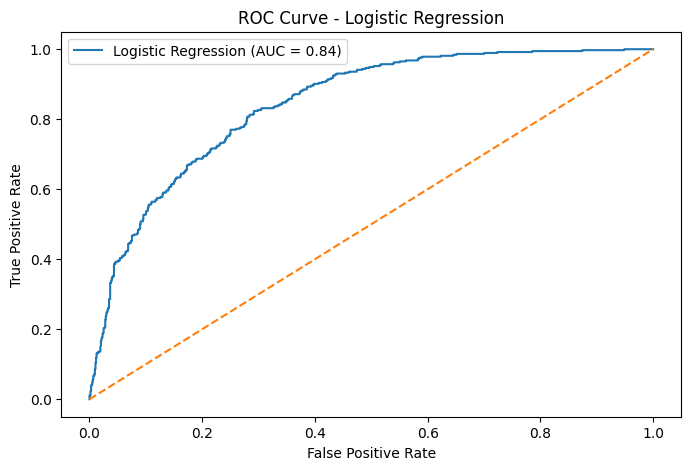

In [529]:
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)

plt.figure(figsize=(8, 5))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {roc_auc:.2f})"
)

plt.plot([0, 1], [0, 1], linestyle="--")

plt.title("ROC Curve - Logistic Regression")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()

plt.show()

### Interpretation

The Logistic Regression model achieved a ROC-AUC of 0.842, indicating good ability to distinguish between customers who churn and those who do not churn.

The ROC curve also shows that the model performs substantially better than random classification, represented by the diagonal reference line.

### 7.5 Random Forest

Random Forest is used as a second classification model to capture non-linear relationships between customer characteristics and churn.

Unlike Logistic Regression, Random Forest can model more complex interactions between features and also provides feature importance information.

In [530]:
random_forest_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestClassifier(
                n_estimators=300,
                random_state=42,
                class_weight="balanced"
            )
        )
    ]
)

In [531]:
random_forest_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['tenure', 'MonthlyCharges',
                                                   'TotalCharges']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  ['gender', 'SeniorCitizen',
                                                   'Partner', 'Dependents',
                                                   'PhoneService',
                                                   'MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
                                                   'OnlineBackup',
                                                   'DeviceProtection',
                                                   'TechSupport', 'StreamingTV',
                                                   'StreamingMovies',
                                                   'Contract',
                                                   'PaperlessBilling',
                                                   'PaymentMethod',
                                                   'AdditionalServicesCount'])])),
                ('model',
                 RandomForestClassifier(class_weight='balanced',
                                        n_estimators=300, random_state=42))])

In [532]:
rf_pred = random_forest_pipeline.predict(X_test)
rf_pred_proba = random_forest_pipeline.predict_proba(X_test)[:, 1]

### 7.5.1 Random Forest Evaluation

The Random Forest model is evaluated using the same performance metrics as the Logistic Regression baseline to ensure a consistent comparison.

In [533]:
rf_accuracy = accuracy_score(y_test, rf_pred)
rf_precision = precision_score(y_test, rf_pred)
rf_recall = recall_score(y_test, rf_pred)
rf_f1 = f1_score(y_test, rf_pred)
rf_roc_auc = roc_auc_score(y_test, rf_pred_proba)

print(f"Accuracy:  {rf_accuracy:.4f}")
print(f"Precision: {rf_precision:.4f}")
print(f"Recall:    {rf_recall:.4f}")
print(f"F1-Score:  {rf_f1:.4f}")
print(f"ROC-AUC:   {rf_roc_auc:.4f}")

Accuracy:  0.7857
Precision: 0.6286
Recall:    0.4706
F1-Score:  0.5382
ROC-AUC:   0.8220


### 7.5.2 Random Forest Confusion Matrix

The confusion matrix is used to examine how the Random Forest model classifies churned and non-churned customers.

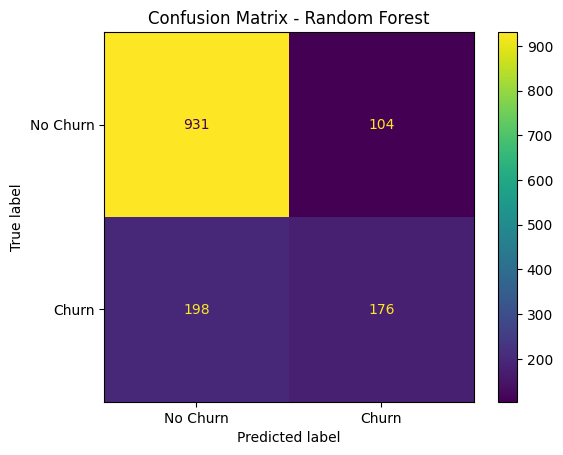

In [534]:
rf_cm = confusion_matrix(y_test, rf_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=rf_cm,
    display_labels=["No Churn", "Churn"]
)

disp.plot()

plt.title("Confusion Matrix - Random Forest")
plt.show()

In [535]:
rf_cm

array([[931, 104],
       [198, 176]], dtype=int64)

### Interpretation

The Random Forest model correctly identifies 931 non-churned customers and 176 churned customers.

However, 198 churned customers are incorrectly classified as non-churned. These false negatives represent customers who are at risk of leaving but are not identified by the model.

The model also incorrectly predicts churn for 104 customers who ultimately do not churn, resulting in false positive predictions.

Overall, the Random Forest model performs below the Logistic Regression baseline on the current test set based on accuracy, recall, F1-score, and ROC-AUC.

### 7.5.3 Random Forest Feature Importance

Feature importance is examined to identify which customer characteristics contribute most to the Random Forest model's predictions.

In [536]:
rf_model = random_forest_pipeline.named_steps["model"]
rf_preprocessor = random_forest_pipeline.named_steps["preprocessor"]

feature_names = rf_preprocessor.get_feature_names_out()

feature_importance = pd.Series(
    rf_model.feature_importances_,
    index=feature_names
).sort_values(ascending=False)

feature_importance.head(10)

num__TotalCharges                      0.169356
num__tenure                            0.165785
num__MonthlyCharges                    0.141221
cat__Contract_Two year                 0.054321
cat__InternetService_Fiber optic       0.044636
cat__PaymentMethod_Electronic check    0.037181
cat__Contract_One year                 0.026563
cat__gender_Male                       0.024747
cat__PaperlessBilling_Yes              0.024318
cat__OnlineSecurity_Yes                0.023923
dtype: float64

### Random Forest Feature Importance

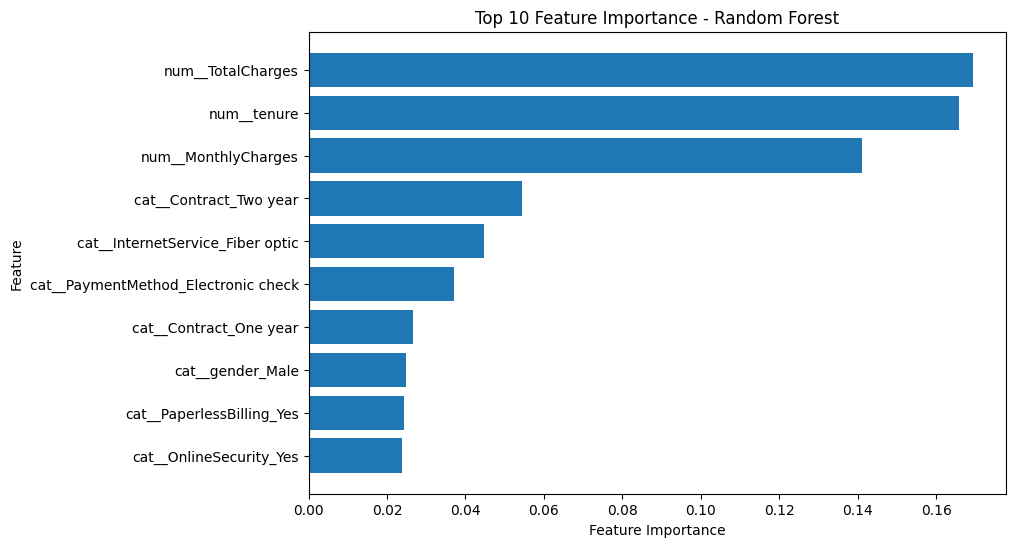

In [537]:
top_features = feature_importance.head(10).sort_values()

plt.figure(figsize=(9, 6))

plt.barh(
    top_features.index,
    top_features.values
)

plt.title("Top 10 Feature Importance - Random Forest")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.show()

### Interpretation

The Random Forest feature importance analysis shows that `TotalCharges`, `tenure`, and `MonthlyCharges` are the three most important features used by the model.

Contract type, fiber optic internet service, and electronic check payment method also contribute substantially to the model's predictions.

These findings are broadly consistent with the exploratory analysis, where contract type, monthly charges, internet service, and payment method showed notable differences in churn rates.

Feature importance indicates predictive contribution rather than causation.

### 7.6 XGBoost

XGBoost is used as a gradient boosting classification model to evaluate whether a boosting approach can improve churn prediction performance compared with Logistic Regression and Random Forest.

In [538]:
xgb_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            XGBClassifier(
                n_estimators=300,
                learning_rate=0.05,
                max_depth=4,
                subsample=0.8,
                colsample_bytree=0.8,
                eval_metric="logloss",
                random_state=42
            )
        )
    ]
)

In [539]:
xgb_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['tenure', 'MonthlyCharges',
                                                   'TotalCharges']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore'),
                                                  ['gender', 'SeniorCitizen',
                                                   'Partner', 'Dependents',
                                                   'PhoneService',
                                                   'MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
                                                   'OnlineBackup',
                                                   'DeviceProtection',
                                                   'TechSuppo...
                               feature_types=None, gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.05,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=4, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=300, n_jobs=None,
                               num_parallel_tree=None, random_state=42, ...))])

In [540]:
xgb_pred = xgb_pipeline.predict(X_test)
xgb_pred_proba = xgb_pipeline.predict_proba(X_test)[:, 1]

### 7.6.2 XGBoost Evaluation

The XGBoost model is evaluated using the same performance metrics as the previous models to ensure a consistent comparison.

In [541]:
xgb_accuracy = accuracy_score(y_test, xgb_pred)
xgb_precision = precision_score(y_test, xgb_pred)
xgb_recall = recall_score(y_test, xgb_pred)
xgb_f1 = f1_score(y_test, xgb_pred)
xgb_roc_auc = roc_auc_score(y_test, xgb_pred_proba)

print(f"Accuracy:  {xgb_accuracy:.4f}")
print(f"Precision: {xgb_precision:.4f}")
print(f"Recall:    {xgb_recall:.4f}")
print(f"F1-Score:  {xgb_f1:.4f}")
print(f"ROC-AUC:   {xgb_roc_auc:.4f}")

Accuracy:  0.8034
Precision: 0.6633
Recall:    0.5267
F1-Score:  0.5872
ROC-AUC:   0.8403


### 7.6.3 XGBoost Confusion Matrix

The confusion matrix is used to examine how the XGBoost model classifies churned and non-churned customers.

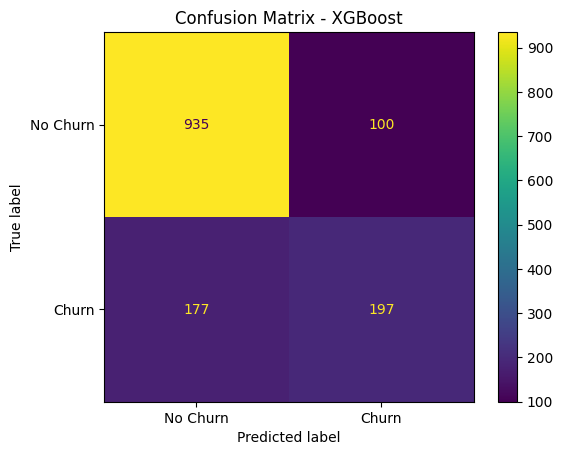

In [542]:
xgb_cm = confusion_matrix(y_test, xgb_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=xgb_cm,
    display_labels=["No Churn", "Churn"]
)

disp.plot()

plt.title("Confusion Matrix - XGBoost")
plt.show()

In [543]:
xgb_cm

array([[935, 100],
       [177, 197]], dtype=int64)

### Interpretation

The XGBoost model correctly identifies 197 churned customers and 935 non-churned customers.

However, 177 churned customers are incorrectly classified as non-churned, resulting in a recall of 52.67%.

Compared with the Logistic Regression baseline, XGBoost identifies fewer churned customers and achieves a lower recall and F1-score on the test set.

Overall, XGBoost performs competitively but does not outperform Logistic Regression on the current evaluation metrics.

### 7.6.4 XGBoost Feature Importance

Feature importance is examined to identify the variables that contribute most to the XGBoost model's predictions.

In [544]:
xgb_model = xgb_pipeline.named_steps["model"]
xgb_preprocessor = xgb_pipeline.named_steps["preprocessor"]

xgb_feature_names = xgb_preprocessor.get_feature_names_out()

xgb_feature_importance = pd.Series(
    xgb_model.feature_importances_,
    index=xgb_feature_names
).sort_values(ascending=False)

xgb_feature_importance.head(10)

cat__InternetService_Fiber optic           0.202961
cat__Contract_Two year                     0.193616
cat__Contract_One year                     0.097672
cat__InternetService_No                    0.079549
cat__OnlineSecurity_No internet service    0.053798
cat__PaymentMethod_Electronic check        0.038714
num__tenure                                0.027454
cat__StreamingMovies_Yes                   0.027227
cat__OnlineSecurity_Yes                    0.020702
cat__PaperlessBilling_Yes                  0.019952
dtype: float32

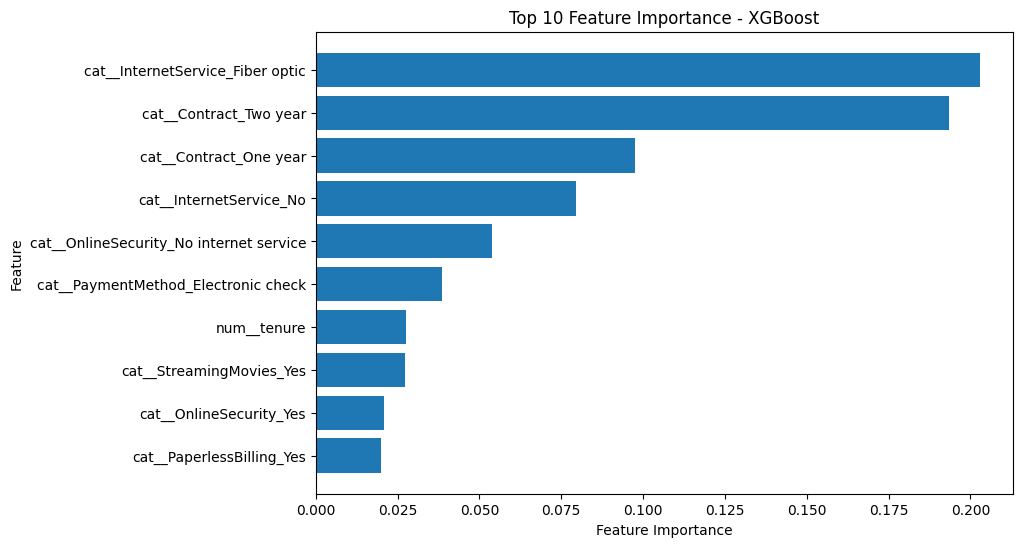

In [545]:
top_xgb_features = (
    xgb_feature_importance
    .head(10)
    .sort_values()
)

plt.figure(figsize=(9, 6))

plt.barh(
    top_xgb_features.index,
    top_xgb_features.values
)

plt.title("Top 10 Feature Importance - XGBoost")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.show()

### Interpretation

The XGBoost feature importance analysis shows that `InternetService_Fiber optic` and `Contract_Two year` are the most important features used by the model.

Internet service type, contract type, and several service-related variables contribute substantially to the model's predictions.

The importance of payment method and tenure also indicates that these customer characteristics provide useful information for churn prediction.

Feature importance represents predictive contribution within the model and should not be interpreted as evidence of causation.

### 7.7 Model Comparison

The performance of the three classification models is compared using accuracy, precision, recall, F1-score, and ROC-AUC.

Using multiple evaluation metrics provides a more comprehensive assessment of model performance, particularly because identifying customers at risk of churn is an important objective.

In [546]:
model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "XGBoost"
    ],
    "Accuracy": [
        accuracy,
        rf_accuracy,
        xgb_accuracy
    ],
    "Precision": [
        precision,
        rf_precision,
        xgb_precision
    ],
    "Recall": [
        recall,
        rf_recall,
        xgb_recall
    ],
    "F1-Score": [
        f1,
        rf_f1,
        xgb_f1
    ],
    "ROC-AUC": [
        roc_auc,
        rf_roc_auc,
        xgb_roc_auc
    ]
})

model_comparison.round(4)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.8027,0.6481,0.5615,0.6017,0.8424
1,Random Forest,0.7857,0.6286,0.4706,0.5382,0.8220
2,XGBoost,0.8034,0.6633,0.5267,0.5872,0.8403


### 7.7.1 Final Model Selection

Based on the test-set results, Logistic Regression achieved the strongest overall performance among the three evaluated models.

It achieved an accuracy of 80.27%, precision of 64.81%, recall of 56.15%, F1-score of 60.17%, and ROC-AUC of 84.24%.

XGBoost performed competitively, achieving a slightly higher accuracy of 80.34% and precision of 66.33%. However, Logistic Regression achieved higher recall, F1-score, and ROC-AUC than XGBoost.

Random Forest produced the lowest performance across the evaluated metrics, with an accuracy of 78.57%, recall of 47.06%, F1-score of 53.82%, and ROC-AUC of 82.20%.

Therefore, Logistic Regression is selected as the final model for this project. Its strong overall performance, combined with its simplicity and interpretability, makes it the most suitable model for the current churn prediction task.

## 8. Business Insights & Recommendations

The analysis identified several customer characteristics associated with higher churn rates. These findings can be used to support customer retention strategies and help the business prioritize customers who may be at greater risk of churn.

### 8.1 Key Churn Drivers

The exploratory analysis identified several notable churn patterns:

- Customers on month-to-month contracts have substantially higher churn rates than customers on one-year or two-year contracts.
- Customers with higher monthly charges show higher churn rates than customers with lower monthly charges.
- Fiber optic customers show a substantially higher churn rate than DSL and customers without internet service.
- Electronic check users have a notably higher churn rate than customers using other payment methods.
- Customers with shorter tenure tend to show higher churn risk.
- Customers with fewer additional services generally show higher churn rates.

### 8.2 Model-Based Insights

The machine learning models provide additional insight into the characteristics that contribute to churn prediction.

The Random Forest model identified `TotalCharges`, `tenure`, and `MonthlyCharges` as its most important features.

The XGBoost model identified `InternetService_Fiber optic`, `Contract_Two year`, and internet-service-related variables among its most important features.

These results complement the exploratory analysis and indicate that customer tenure, charges, contract type, and internet service characteristics contain useful predictive information.

### 8.3 Business Recommendations

Based on the findings, the following retention strategies could be considered:

1. **Target month-to-month customers:** Customers without long-term contracts should receive targeted retention offers and incentives to encourage longer contract commitments.

2. **Focus on high-charge customers:** Customers with higher monthly charges could be prioritized for proactive retention campaigns and personalized offers.

3. **Monitor fiber optic customers:** The relatively high churn rate among fiber optic customers suggests that this customer segment warrants further investigation and targeted retention efforts.

4. **Review electronic check customers:** Customers using electronic check payments show a notably higher churn rate. The business could investigate whether payment experience, billing friction, or customer characteristics contribute to this pattern.

5. **Engage newer customers early:** Customers with shorter tenure could receive onboarding and engagement campaigns designed to increase early-stage satisfaction and reduce early churn.

6. **Use predictive scoring for prioritization:** The final Logistic Regression model can be used to identify customers with higher predicted churn probability so that retention resources can be focused on the customers most likely to benefit.

## 9. Customer Churn Risk Scoring

The final Logistic Regression model is used to estimate the probability of churn for each customer.

These predicted probabilities can be used to prioritize customers for targeted retention activities.

In [547]:
df["ChurnProbability"] = logistic_pipeline.predict_proba(X)[:, 1]

In [548]:
df[["ChurnProbability"]].describe()

,ChurnProbability
count,7043.000000
mean,0.265750
std,0.245032
min,0.001873
25%,0.043525
50%,0.186871
75%,0.461702
max,0.851763


### 9.1 Customer Risk Segmentation

Customers are segmented into low-, medium-, and high-risk groups based on their predicted churn probability.

- Low Risk: predicted churn probability below 20%
- Medium Risk: predicted churn probability between 20% and 50%
- High Risk: predicted churn probability above 50%

These thresholds are used for customer prioritization and should be further calibrated based on the business cost of false positives and false negatives.

In [549]:
df["RiskLevel"] = pd.cut(
    df["ChurnProbability"],
    bins=[-float("inf"), 0.20, 0.50, float("inf")],
    labels=["Low Risk", "Medium Risk", "High Risk"]
)

In [550]:
risk_counts = df["RiskLevel"].value_counts().reindex(
    ["Low Risk", "Medium Risk", "High Risk"]
)

risk_counts

RiskLevel
Low Risk       3666
Medium Risk    1796
High Risk      1581
Name: count, dtype: int64

### 9.2 Risk Distribution

The distribution of customers across the three predicted churn-risk segments is visualized to provide a clear overview of the customer population requiring different levels of retention attention.

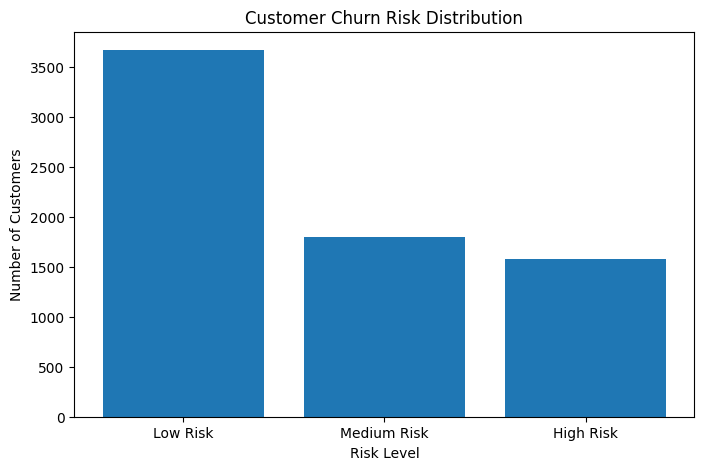

In [551]:
risk_counts = df["RiskLevel"].value_counts().reindex(
    ["Low Risk", "Medium Risk", "High Risk"]
)

plt.figure(figsize=(8, 5))

plt.bar(
    risk_counts.index,
    risk_counts.values
)

plt.title("Customer Churn Risk Distribution")
plt.xlabel("Risk Level")
plt.ylabel("Number of Customers")

plt.show()

### Interpretation

The model classifies 1,581 customers as high risk, representing approximately 22.5% of the customer base.

A further 1,796 customers fall into the medium-risk segment, while 3,666 customers are classified as low risk.

This segmentation can help the business prioritize retention resources, with high-risk customers receiving the most immediate attention.

### 9.3 High-Risk Customer Profile

The characteristics of customers classified as high risk are examined to better understand the customer segments that may require retention attention.

In [552]:
high_risk_customers = df[df["RiskLevel"] == "High Risk"].copy()

In [553]:
high_risk_customers.shape

(1581, 24)

In [554]:
high_risk_customers[[
    "tenure",
    "MonthlyCharges",
    "TotalCharges",
    "ChurnProbability"
]].describe()

,tenure,MonthlyCharges,TotalCharges,ChurnProbability
count,1581.000000,1581.000000,1581.000000,1581.000000
mean,11.509171,80.707274,1025.450917,0.648003
std,11.624862,17.996321,1151.910930,0.087308
min,1.000000,23.450000,23.450000,0.500023
25%,2.000000,73.850000,154.800000,0.574830
50%,7.000000,81.700000,576.700000,0.644921
75%,17.000000,94.200000,1483.250000,0.717887
max,60.000000,113.200000,6401.250000,0.851763


### Interpretation

The high-risk customer segment consists of 1,581 customers with an average predicted churn probability of 64.8%.

These customers have an average tenure of approximately 11.5 months, indicating that the high-risk group is generally characterized by relatively short customer relationships.

The average monthly charge is approximately $80.71, while the average total charges are approximately $1,025.45.

Overall, the profile suggests that high-risk customers tend to have relatively short tenure and moderately high monthly charges. These characteristics can help the business identify and prioritize customers who may require targeted retention efforts.

### 9.3.1 High-Risk Customers by Contract

The contract distribution of high-risk customers is examined to identify which contract segments contain the largest number of customers with elevated predicted churn risk.

In [555]:
high_risk_contract = high_risk_customers["Contract"]

high_risk_contract.value_counts()

Contract
Month-to-month    1577
One year             4
Name: count, dtype: int64

### Interpretation

The high-risk customer segment is overwhelmingly concentrated among month-to-month contract customers.

Out of 1,581 high-risk customers, 1,577 have month-to-month contracts, while only 4 have one-year contracts. No high-risk customers in this segment have two-year contracts.

This finding highlights month-to-month customers as the primary contract segment requiring retention attention.

### 9.3.2 High-Risk Customers by Internet Service

The internet service distribution of high-risk customers is examined to identify which internet service segments contain the largest number of customers with elevated predicted churn risk.

In [556]:
high_risk_internet = high_risk_customers["InternetService"]

high_risk_internet.value_counts()

InternetService
Fiber optic    1399
DSL             182
Name: count, dtype: int64

### Interpretation

The high-risk customer analysis shows that **Fiber optic customers make up the vast majority of the high-risk group**, with 1,399 customers classified as high risk.

In comparison, **182 high-risk customers use DSL**, while no high-risk customers are classified under the **No internet service** category.

This indicates that Fiber optic customers represent the main internet-service segment among customers with elevated predicted churn risk. Therefore, this customer group may require particular attention in retention strategies.

These results are based on **predicted churn risk** and indicate an association within the model; they should not be interpreted as evidence that fiber optic service itself causes churn.

### 9.3.3 High-Risk Customers by Payment Method

The payment method distribution of high-risk customers is examined to identify which payment segments contain the largest number of customers with elevated predicted churn risk.

In [557]:
high_risk_payment = high_risk_customers["PaymentMethod"]

In [558]:
high_risk_payment.value_counts()

PaymentMethod
Electronic check             1176
Mailed check                  158
Bank transfer (automatic)     130
Credit card (automatic)       117
Name: count, dtype: int64

### Interpretation

The high-risk customer analysis shows that **Electronic check customers make up the largest share of the high-risk group**, with 1,176 customers classified as high risk.

Mailed check customers account for 158 high-risk customers, followed by 130 customers using bank transfer (automatic) and 117 customers using credit card (automatic).

This indicates that customers using **electronic check payments are particularly prominent among customers with elevated predicted churn risk**. Therefore, this payment segment may require particular attention in retention strategies and further investigation of the customer or payment experience.

These results are based on **predicted churn risk** and indicate an association within the model; they should not be interpreted as evidence that electronic check payment itself causes churn.

### 9.3.4 High-Risk Customer Profile Summary

The high-risk customer analysis reveals a clear concentration across several customer characteristics.

Most high-risk customers are on month-to-month contracts, use fiber optic internet service, and use electronic check as their payment method.

This profile can help the business prioritize retention efforts by focusing on customers who share multiple characteristics associated with elevated predicted churn risk.

These patterns represent associations identified in the dataset and model predictions rather than evidence of direct causation.

### 9.4 Final Recommendations

Based on the exploratory analysis, machine learning results, and customer risk segmentation, the following recommendations can be considered:

1. **Prioritize high-risk customers:** Customers with predicted churn probabilities above 50% should receive the highest priority for retention activities.
2. **Focus on month-to-month customers:** The high-risk customer profile is strongly concentrated among month-to-month customers. The business could offer incentives that encourage customers to move to longer-term contracts.
3. **Investigate fiber optic customers:** Fiber optic customers represent a large proportion of the high-risk segment. Customer satisfaction, service quality, and pricing should be investigated for this group.
4. **Review electronic check customers:** Electronic check users represent the largest payment-method segment among high-risk customers. The business could investigate the payment experience and potential billing-related issues.
5. **Engage customers early:** High-risk customers have relatively short tenure on average. Early engagement, onboarding support, and proactive communication could help reduce early-stage churn.
6. **Use predictive churn scoring:** The Logistic Regression model can be used to assign churn probabilities to customers and prioritize retention resources based on predicted risk.

These recommendations should be validated through targeted retention experiments and monitored using appropriate business metrics such as retention rate, churn rate, and customer lifetime value.

## 10. Power BI Export

The final customer-level dataset and model comparison results were exported as CSV files for Power BI dashboard development.

In [563]:
df.to_csv("customer_churn_data.csv", index=False)
model_comparison.to_csv("model_comparison.csv", index=False)

print("Power BI files created successfully.")
print("customer_churn_data.csv:", df.shape)
print("model_comparison.csv:", model_comparison.shape)

Power BI files created successfully.
customer_churn_data.csv: (7043, 24)
model_comparison.csv: (3, 6)


# 11. Conclusion

This project analyzed customer churn using exploratory data analysis, statistical testing, and machine learning classification models.

The analysis identified several important churn patterns. Month-to-month contracts, higher monthly charges, fiber optic internet service, and electronic check payments were associated with higher churn rates.

Three machine learning models were evaluated: Logistic Regression, Random Forest, and XGBoost. Logistic Regression achieved an accuracy of 80.27%, precision of 64.81%, recall of 56.15%, F1-score of 60.17%, and ROC-AUC of 84.24%. Therefore, Logistic Regression was selected as the final model.

The final model was also used to estimate individual customer churn probabilities and classify customers into low-, medium-, and high-risk groups. This risk segmentation provides a practical way for the business to prioritize retention efforts.

Overall, the project demonstrates how customer data and machine learning can be used not only to predict churn but also to support data-driven customer retention strategies.